# Directional Implicit LJ From LJ Data

This notebook generates target geometries with `LJFF`, perturbs the LJ parameters, then recovers them with `DirectionalImplicitMultipleSystemOptimizer`.


In [1]:
import sys
import os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..', '..', '..')))

import copy
import torch
import numpy as np
import matplotlib.pyplot as plt

from geomatry.opt_Energy_approximated.optimizer import DirectionalImplicitMultipleSystemOptimizer
from geomatry.opt.loss import rmsd_loss
from geomatry.ff.graph import get_given_graph_builder
from geomatry.ff.springs import LJFF, _random_lj_systems, _random_lj_ff_param


In [2]:
def min_pair_distance(Ra: torch.Tensor) -> float:
    Ra = Ra.detach()
    dmat = torch.cdist(Ra, Ra)
    return float(torch.min(dmat + torch.eye(Ra.shape[0], device=Ra.device) * 1e6))


In [3]:
systemN = 20
N = 10
N_pairs = 30
max_Za = 3
fixed_atom_indices = [0, 1]

Ras, Zas, idx_is, idx_js = _random_lj_systems(systemN, N, N_pairs, max_Za, start_Za=1)
epsilon, sigma = _random_lj_ff_param(max_Za, epsilon_range=(0.7, 2.0), sigma_range=(0.9, 1.1))

ff = LJFF(max_Za)
ff.reset_parameters(epsilon, sigma)
params_star = copy.deepcopy(ff.state_dict())

graph_builders = [get_given_graph_builder(idx_i, idx_j) for idx_i, idx_j in zip(idx_is, idx_js)]

print('sample target epsilon', epsilon[1:, 1:].mean().item())
print('sample target sigma', sigma[1:, 1:].mean().item())
print('sample min distances', [min_pair_distance(Ra) for Ra in Ras[:3]])


sample target epsilon 1.4369905296928258
sample target sigma 1.0102297646804557
sample min distances [0.7073230098157679, 0.6993413780385572, 0.49575534602506777]


In [4]:
optimizer = DirectionalImplicitMultipleSystemOptimizer(
    Ras, Zas, graph_builders, ff, rmsd_loss,
    params_star=params_star,
    fixed_atom_indices=fixed_atom_indices,
    fmax=1e-5
)

perturbed_epsilon = torch.abs(epsilon.clone() + 0.3 * torch.randn_like(epsilon))
perturbed_sigma = torch.abs(sigma.clone() + 0.07 * torch.randn_like(sigma))
ff.reset_parameters(perturbed_epsilon, perturbed_sigma)
params_0 = copy.deepcopy(ff.state_dict())

print('start epsilon mean', params_0['epsilon'][1:, 1:].mean().item())
print('start sigma mean', params_0['sigma'][1:, 1:].mean().item())
print('target epsilon mean', params_star['epsilon'][1:, 1:].mean().item())
print('target sigma mean', params_star['sigma'][1:, 1:].mean().item())


start epsilon mean 1.230371486669936
start sigma mean 1.022077419735492
target epsilon mean 1.4369905296928258
target sigma mean 1.0102297646804557


In [5]:
new_params = optimizer.optimize(params_0, lr=1e-3, epoch=15001, print_period=5000, e_size=0.2, eN=9, sg=2)
print('optimization complete')


  0%|          | 4/15001 [00:00<14:16, 17.51it/s]

Iteration 0, total_scale: 2.466430e-01


 33%|███▎      | 5005/15001 [03:23<06:10, 26.98it/s]

Iteration 5000, total_scale: 3.942346e-04


 67%|██████▋   | 10004/15001 [06:53<03:05, 26.96it/s]

Iteration 10000, total_scale: 2.967499e-03


100%|██████████| 15001/15001 [10:20<00:00, 24.16it/s]

Iteration 15000, total_scale: 9.235193e-04
optimization complete


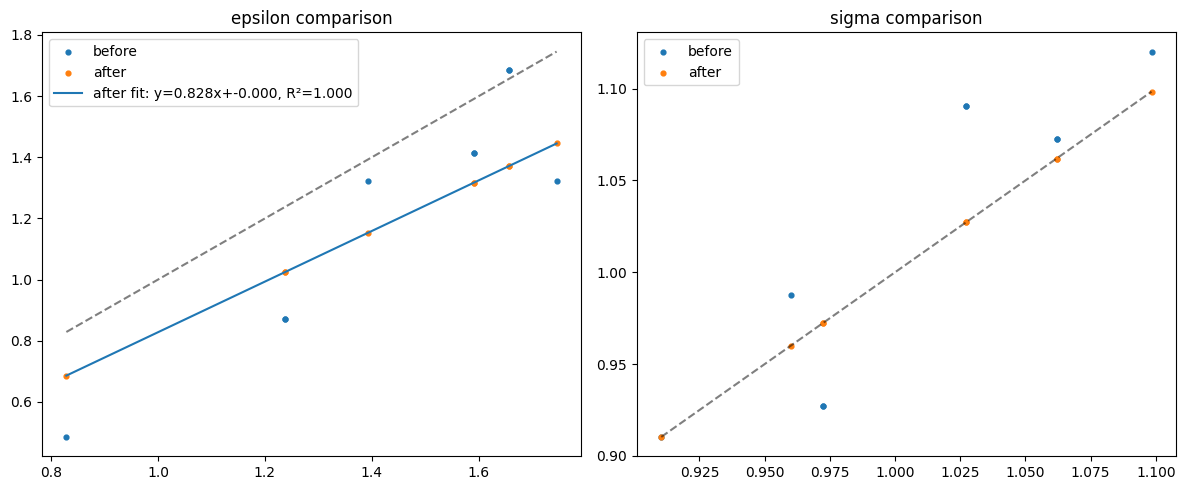

In [8]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
target_eps = params_star['epsilon'][1:, 1:].detach().reshape(-1).cpu().numpy()
before_eps = params_0['epsilon'][1:, 1:].detach().reshape(-1).cpu().numpy()
after_eps = new_params['epsilon'][1:, 1:].detach().reshape(-1).cpu().numpy()
plt.scatter(target_eps, before_eps, label='before', s=12)
plt.scatter(target_eps, after_eps, label='after', s=12)
plt.plot([target_eps.min(), target_eps.max()], [target_eps.min(), target_eps.max()], 'k--', alpha=0.5)
plt.title('epsilon comparison')

# Linear fits: y = a*x + b
def add_linear_fit(x, y, label, linestyle='-'):
    mask = np.isfinite(x) & np.isfinite(y)
    x_fit_data = x[mask]
    y_fit_data = y[mask]

    a, b = np.polyfit(x_fit_data, y_fit_data, 1)
    y_pred = a * x_fit_data + b

    r2 = 1 - np.sum((y_fit_data - y_pred)**2) / np.sum((y_fit_data - y_fit_data.mean())**2)

    x_line = np.linspace(x_fit_data.min(), x_fit_data.max(), 200)
    y_line = a * x_line + b

    plt.plot(
        x_line, y_line, linestyle,
        label=f'{label} fit: y={a:.3f}x+{b:.3f}, R²={r2:.3f}'
    )

add_linear_fit(target_eps, after_eps, 'after')

plt.legend()

plt.subplot(1, 2, 2)
target_sigma = params_star['sigma'][1:, 1:].detach().reshape(-1).cpu().numpy()
before_sigma = params_0['sigma'][1:, 1:].detach().reshape(-1).cpu().numpy()
after_sigma = new_params['sigma'][1:, 1:].detach().reshape(-1).cpu().numpy()
plt.scatter(target_sigma, before_sigma, label='before', s=12)
plt.scatter(target_sigma, after_sigma, label='after', s=12)
plt.plot([target_sigma.min(), target_sigma.max()], [target_sigma.min(), target_sigma.max()], 'k--', alpha=0.5)
plt.title('sigma comparison')
plt.legend()


plt.tight_layout()
